# 4. Signal generator module (PMCW, CDM-MIMO): `RadarSensorView` + `AntennaModel` → `RadarCpiData`

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from osi_hfss import decode, modules
from osi_hfss.analysis import detection_table, expected_positions
from osi_hfss.data import load
from osi_hfss.messages import over_osi, preview
from osi_hfss.plots import (
    plot_detections_world,
    plot_pmcw_codes,
    plot_pmcw_correlation,
    plot_pmcw_raw,
    plot_range_doppler,
    plot_scene,
)

# The inputs: OSI messages of the environment and the antenna modules for the corner radar
sensor_view = over_osi(load("corner.sensorview.bin"))
rays = sensor_view.radar_sensor_view[0]
antenna = over_osi(load("corner.antennamodel.bin"))
expected = expected_positions(rays)  # direct reflections, for comparison only

# The scene in world coordinates, for the plots only: front-left corner radar at 45 deg, 79 GHz
ground_truth = load("corner.groundtruth.bin")
host = next(o for o in ground_truth.moving_object if o.id.value == ground_truth.host_vehicle_id.value)
host_speed = host.base.velocity.x
scene = load("corner.scene.json")  # object names and radar properties, not in OSI
NAMES = {o["id"]: o["name"] for o in scene["objects"]}
config = rays.view_configuration
print(f"{len(rays.reflection)} reflections from {len(expected)} objects in the field of view")

  SensorView              3.0 kB
  AntennaModel        16798.2 kB
15 reflections from 5 objects in the field of view


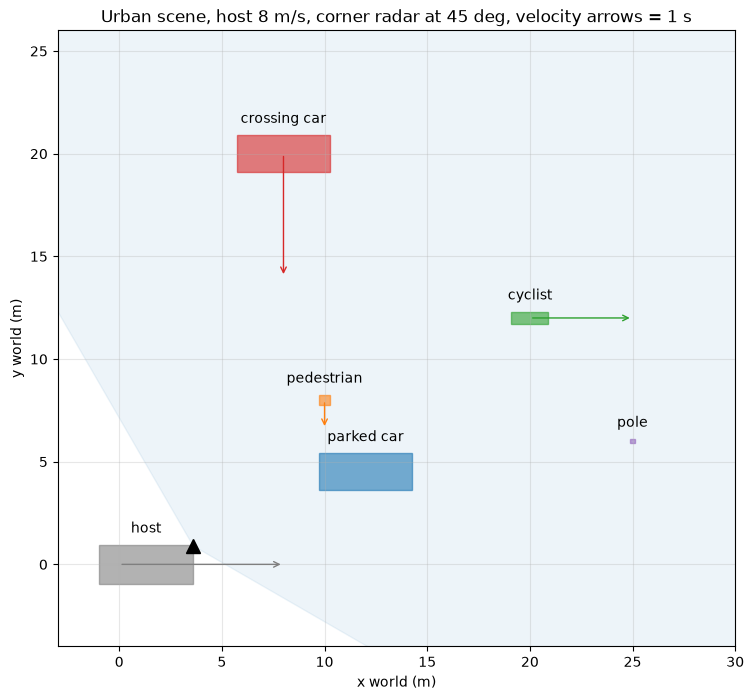

In [2]:
SCENE = dict(reach=38.0, names=NAMES, xlim=(-3, 30), ylim=(-4, 26))
fig, ax = plt.subplots(figsize=(9, 8))
plot_scene(ground_truth, config.mounting_position, config.field_of_view_horizontal, ax=ax, velocities=True,
           title=f"Urban scene, host {host_speed:.0f} m/s, corner radar at 45 deg, velocity arrows = 1 s",
           **SCENE)
plt.show()

## Codes and code-division MIMO

L = 1023 chips, code period 1.023 us, slow-time interval 32.74 us
range resolution 0.150 m, 255 bins per Tx = 38.2 m
unambiguous range rate ±29 m/s, CPI 8.38 ms


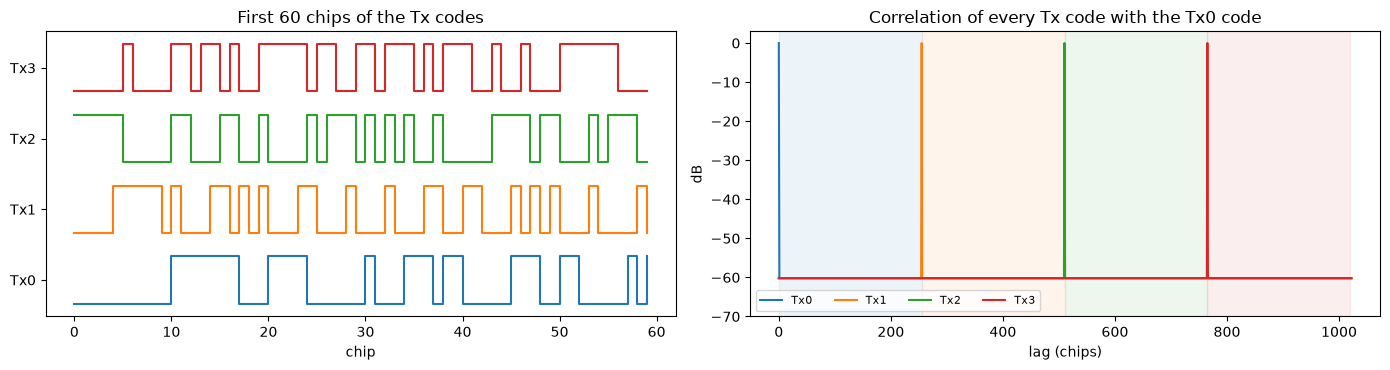

In [3]:
settings = load("corner.signal_generator.json")  # generator settings, not part of OSI
description = load("corner.generator_description.json")
pmcw, waveform = description["config"], description["waveform"]
L, W = waveform["code_length"], waveform["range_bins"]
print(f"L = {L} chips, code period {pmcw['code_period'] * 1e6:.3f} us, slow-time interval {pmcw['slow_time_interval'] * 1e6:.2f} us")
print(f"range resolution {waveform['range_resolution']:.3f} m, {W} bins per Tx = {W * waveform['range_resolution']:.1f} m")
print(f"unambiguous range rate ±{waveform['wavelength'] / (4 * pmcw['slow_time_interval']):.0f} m/s, "
      f"CPI {pmcw['slow_samples'] * pmcw['slow_time_interval'] * 1e3:.2f} ms")

# The module configured for the raw output
raw_data, correlations = modules.pmcw_signal_generator_with_analysis(sensor_view, antenna, settings, raw=True)
plot_pmcw_codes(waveform, correlations["code_correlation_db"])
plt.show()

## Generate: raw chips vs. hardware correlator output

raw        PHYSICAL FAST_TIME shape (4, 256, 1023), noise  -54.9 dBm per cell, RadarCpiData  8.38 MB
correlator VIRTUAL  RANGE     shape (16, 256, 255), noise  -24.8 dBm per cell, RadarCpiData  8.36 MB


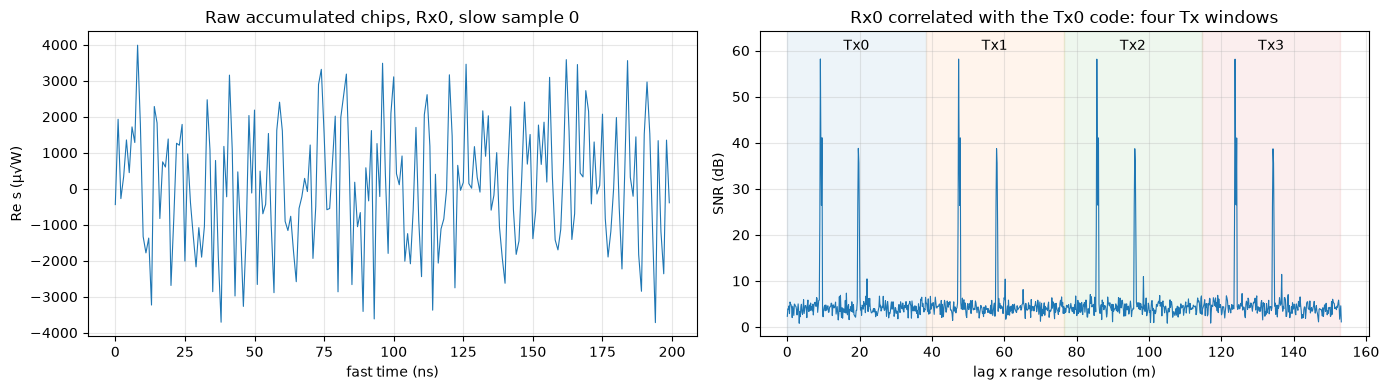

In [4]:
cpi_data = modules.pmcw_signal_generator(sensor_view, antenna, settings)  # the module output
raw, cpi = raw_data.cpi_frame[0], cpi_data.cpi_frame[0]
for name, c, message in (("raw", raw, raw_data), ("correlator", cpi, cpi_data)):
    print(f"{name:10s} {decode.enum_name(c.channel[0], 'kind'):8s} {decode.enum_name(c.fast_axis, 'domain'):9s} shape {decode.cpi_cube(c).shape}, "
          f"noise {10 * np.log10(c.noise_power / 1e-3):6.1f} dBm per cell, RadarCpiData {message.ByteSize() / 1e6:5.2f} MB")

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
plot_pmcw_raw(raw, ax=a)
plot_pmcw_correlation(correlations["lag_range"], correlations["raw_correlation_snr_db"], waveform, ax=b)
plt.tight_layout(); plt.show()

## Same DSP module as for FMCW

      object | detected: range [m] az [deg] v_r [m/s] SNR [dB] | expected: range [m] az [deg] v_r [m/s]
  parked car |                9.14   -21.75      7.25     79.4 |                9.14   -21.80      7.35
  pedestrian |                9.59     3.00      6.34     63.1 |                9.56     2.97      6.40
crossing car |               19.64    32.00      7.70     60.6 |               19.60    32.03      7.64
     cyclist |               19.79   -11.00      2.49     57.9 |               19.80   -10.91      2.48
        pole |               22.03   -31.75      7.70     31.4 |               22.00   -31.60      7.78


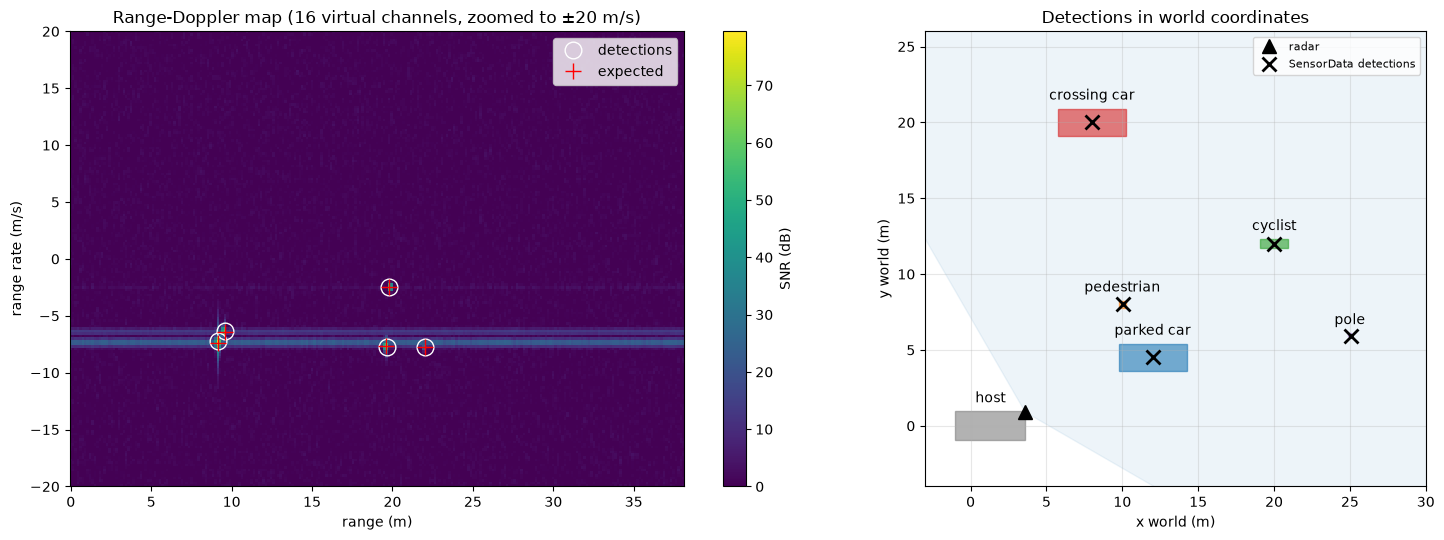

In [5]:
sensor_data, analysis = modules.radar_dsp_with_analysis(cpi_data, antenna)
print(detection_table(sensor_data, expected, NAMES))

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
plot_range_doppler(analysis["range"], analysis["range_rate"], analysis["snr"], sensor_data, expected, ax=a, ylim=(-20, 20),
                   title="Range-Doppler map (16 virtual channels, zoomed to ±20 m/s)")
plot_scene(ground_truth, config.mounting_position, config.field_of_view_horizontal, ax=b,
           title="Detections in world coordinates", **SCENE)
plot_detections_world(sensor_data, config.mounting_position, b, "kx", "SensorData detections")
b.legend(fontsize=8)
plt.tight_layout(); plt.show()

## On the interface

In [6]:
frame = cpi_data.cpi_frame[0]
print("RadarCpiData.cpi_frame[0]:")
print(preview(frame, max_repeated=1, indent="  "))
print("\nSensorData.feature_data.radar_sensor[0]:")
print(preview(sensor_data.feature_data.radar_sensor[0], max_repeated=1, indent="  "))

RadarCpiData.cpi_frame[0]:
  cpi_index: 0
  start_time {
    seconds: 0
    nanos: 0
  }
  fast_axis {
    domain: DOMAIN_RANGE
    size: 255
    spacing: 0.149896
    offset: 0
    window: WINDOW_NONE
  }
  slow_axis {
    domain: DOMAIN_SLOW_TIME
    size: 256
    spacing: 3.2736e-05
    offset: 0
    window: WINDOW_NONE
  }
  channel {
    index: 0
    kind: KIND_VIRTUAL
    rx_index: 0
    tx_index: 0
    position {
      x: 0
      y: -0.0142307
      z: 0
    }
    time_offset: 0
    rx_port: 1
  }
  channel: ... 15 more
  transmitter {
    index: 0
    position {
      x: 0
      y: -0.0113845
      z: 0
    }
    excitation_0 {
      amplitude: 0
      phase: 0
    }
    excitation_1 {
      amplitude: 1
      phase: 0
    }
  }
  transmitter: ... 3 more
  center_frequency: 7.9e+10
  noise_power: 3.29236e-06
  sample_format: SAMPLE_FORMAT_COMPLEX_IQ
  data_encoding: DATA_ENCODING_FLOAT32
  scale_factor: 1
  data: <8.36 MB>
  configuration_id {
    value: 2
  }

SensorData.featu